# 03 — Split pasien 80:10:10 dan preprocessing
Satu pembagian holdout berdasarkan pasien, dengan seed 42. Seluruh stay pasien yang sama masuk subset yang sama.

**Alur:** baca input → split pasien → fit preprocessing pada train → transformasi seluruh subset → periksa → simpan.

Parameter median, mean/std, dan kategori dipelajari dari train saja. Tidak ada fitting menggunakan target, validation atau test.


In [1]:
import sys
print("Python notebook:", sys.executable)

Python notebook: c:\Users\ASUS\AppData\Local\Programs\Python\Python311\python.exe


In [2]:
%pip install numpy==1.26.4 pandas==2.3.3 matplotlib ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Konfigurasi
Periksa `ROOT` dan `STAGE02_RUN`. Biarkan `RESUME_RUN` kosong untuk run baru, lalu **Restart Kernel → Run All**. Dependensi: numpy, pandas, matplotlib, IPython.

Jika melanjutkan proses, isi `RESUME_RUN` dengan ID run notebook ini. Jangan memakai run lima-fold sebelumnya. Setelah mulai, gunakan kode dan pengaturan yang sama untuk resume.


In [3]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import contextmanager
import hashlib
import json
import math
import os
import platform
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("C:\\Users\\ASUS\\Documents\\icu_los")
STAGE02_RUN = "20261019_140043_593718_sequences"
RESUME_RUN = ""  # Kosong: run baru. Isi run Step03 ini untuk resume.
SEED = 42
SPLIT_RATIOS = (0.8, 0.1, 0.1)
ROLES = ("train", "validation", "test")
MIN_FREE_GIB = 20.0
SHOW_LOCAL_IDENTIFIERS = False
IDS = ["ICUSTAY_ID", "SUBJECT_ID", "HADM_ID"]
CATS = ["gender", "admission_type", "first_careunit"]
MISSING, UNKNOWN = ("__MISSING__", "__UNKNOWN__")
OBS_DTYPE = np.dtype([("row", "<i4"), ("value", "<f8")])
print("Project:", ROOT)
print("Source Step02:", STAGE02_RUN)
print("Split:", SPLIT_RATIOS, "| seed:", SEED)


Project: C:\Users\ASUS\Documents\icu_los
Source Step02: 20261019_140043_593718_sequences
Split: (0.8, 0.1, 0.1) | seed: 42


## 2. Fitur klinis
Tiga puluh fitur pertama adalah pengukuran yang boleh di-forward-fill dalam stay yang sama. Tiga belas fitur terakhir adalah volume yang tidak di-forward-fill. Mask observasi tetap berasal dari data asli.


In [4]:
FEATURES = [
    "heart_rate",
    "systolic_bp",
    "diastolic_bp",
    "mean_bp",
    "respiratory_rate",
    "spo2",
    "temperature",
    "chart_glucose",
    "gcs_eye",
    "gcs_verbal",
    "gcs_motor",
    "gcs_total_recorded",
    "lab_glucose",
    "sodium",
    "potassium",
    "chloride",
    "bicarbonate",
    "bun",
    "creatinine",
    "wbc",
    "hemoglobin",
    "hematocrit",
    "platelets",
    "lactate",
    "albumin",
    "bilirubin_total",
    "inr",
    "blood_ph",
    "blood_pco2",
    "blood_po2",
    "crystalloid_recorded_ml",
    "colloid_recorded_ml",
    "blood_product_recorded_ml",
    "oral_recorded_ml",
    "enteral_flush_recorded_ml",
    "parenteral_nutrition_recorded_ml",
    "urine_recorded_ml",
    "chest_drain_recorded_ml",
    "gastric_recorded_ml",
    "jp_drain_recorded_ml",
    "stool_ostomy_recorded_ml",
    "gu_irrigant_in_recorded_ml",
    "gu_irrigant_out_recorded_ml",
]


def require(ok, message):
    if not bool(ok):
        raise ValueError(message)


## 3. Split berdasarkan pasien
Pasien unik diacak tanpa membaca LOS atau nilai klinis. Jumlah validation dan test masing-masing dibulatkan ke atas; sisanya masuk train. Persentase stay dapat berbeda karena jumlah stay per pasien tidak sama.


In [5]:
def make_patient_split(sample, seed, ratios):
    """Acak pasien unik, lalu petakan seluruh stay ke subset pasiennya."""
    require(
        set(sample.columns) == set(["cohort_row"] + IDS),
        "Split hanya menerima row map dan ID, bukan fitur atau target",
    )
    require(
        len(ratios) == 3 and all((x > 0 for x in ratios)) and np.isclose(sum(ratios), 1),
        "Rasio split tidak valid",
    )
    patients = np.sort(sample.SUBJECT_ID.unique())
    require(len(patients) >= 10, "Jumlah pasien terlalu sedikit")
    shuffled = np.random.default_rng(seed).permutation(patients)
    n_test = math.ceil(len(patients) * ratios[2])
    n_validation = math.ceil(len(patients) * ratios[1])
    require(n_test + n_validation < len(patients), "Training set kosong")
    roles = np.full(len(patients), "train", dtype="<U10")
    roles[:n_test] = "test"
    roles[n_test : n_test + n_validation] = "validation"
    patient_split = pd.DataFrame({"SUBJECT_ID": shuffled, "split": roles})
    patient_split = patient_split.sort_values("SUBJECT_ID").reset_index(drop=True)
    assignments = sample.merge(
        patient_split, on="SUBJECT_ID", how="left", validate="many_to_one"
    )
    assignments = assignments.sort_values("cohort_row").reset_index(drop=True)
    return (patient_split, assignments)


def check_splits(sample, patient_split, assignments):
    checks = []

    def check(name, passed):
        require(passed, "Split tidak valid: " + name)
        checks.append({"check": name, "status": "PASS"})

    check(
        "cohort_covered_once",
        len(assignments) == len(sample)
        and assignments.ICUSTAY_ID.is_unique
        and np.array_equal(assignments.ICUSTAY_ID, sample.ICUSTAY_ID)
        and np.array_equal(assignments.cohort_row, sample.cohort_row),
    )
    check(
        "patient_registry_unique_complete",
        patient_split.SUBJECT_ID.is_unique
        and set(patient_split.SUBJECT_ID) == set(sample.SUBJECT_ID),
    )
    check(
        "patient_isolation", assignments.groupby("SUBJECT_ID").split.nunique().eq(1).all()
    )
    check("admission_isolation", assignments.groupby("HADM_ID").split.nunique().eq(1).all())
    check("three_nonempty_subsets", set(assignments.split) == set(ROLES))
    mapping = patient_split.set_index("SUBJECT_ID").split
    check(
        "assignments_match_patient_registry",
        np.array_equal(assignments.split, assignments.SUBJECT_ID.map(mapping)),
    )
    n = sample.SUBJECT_ID.nunique()
    expected = {
        "validation": math.ceil(n * SPLIT_RATIOS[1]),
        "test": math.ceil(n * SPLIT_RATIOS[2]),
    }
    expected["train"] = n - expected["validation"] - expected["test"]
    summary = []
    for role in ROLES:
        subset = assignments.loc[assignments.split.eq(role)]
        check(role + "_patient_count", subset.SUBJECT_ID.nunique() == expected[role])
        summary.append(
            {
                "split": role,
                "patients": subset.SUBJECT_ID.nunique(),
                "icu_stays": len(subset),
                "patient_percentage": 100 * subset.SUBJECT_ID.nunique() / n,
                "stay_percentage": 100 * len(subset) / len(sample),
            }
        )
    return (pd.DataFrame(checks), pd.DataFrame(summary))


## 4. Preprocessing statis
Usia kosong diisi median train, lalu dihitung z-score. Vocabulary kategori berasal dari train. Kategori kosong menjadi `__MISSING__`; kategori baru pada validation/test menjadi `__UNKNOWN__`.


In [6]:
def fit_static(static, train_idx):
    train = static.iloc[train_idx]
    ages = train.age.to_numpy(dtype=np.float64)
    finite = ages[np.isfinite(ages)]
    require(len(finite) > 0, "Seluruh usia train kosong")
    median = float(np.median(finite))
    filled = np.where(np.isfinite(ages), ages, median)
    sd = float(np.std(filled, ddof=0))
    mean = float(filled.mean())
    constant = sd <= 32 * np.finfo(np.float64).eps * max(1.0, abs(mean))
    categories = {c: sorted(set(train[c]) - {MISSING}) + [MISSING, UNKNOWN] for c in CATS}
    names = ["age_z"] + [f"{c}={category}" for c in CATS for category in categories[c]]
    return dict(
        age_median=median,
        age_mean=mean,
        age_std=sd,
        age_scale=1.0 if constant else sd,
        age_zero_variance=bool(constant),
        categories=categories,
        feature_names=names,
        fit_scope="TRAIN_ONLY",
    )


def transform_static(static, params):
    age = static.age.to_numpy(dtype=np.float64)
    age = np.where(np.isfinite(age), age, params["age_median"])
    blocks = [((age - params["age_mean"]) / params["age_scale"])[:, None]]
    unknown_counts = {}
    for feature in CATS:
        vocabulary = params["categories"][feature]
        lookup = {value: i for i, value in enumerate(vocabulary)}
        indices = np.array(
            [lookup.get(value, lookup[UNKNOWN]) for value in static[feature]],
            dtype=np.int64,
        )
        block = np.zeros((len(static), len(vocabulary)), dtype=np.float64)
        block[np.arange(len(static)), indices] = 1
        require(block.sum(axis=1).tolist() == [1.0] * len(static), "One-hot salah")
        blocks.append(block)
        unknown_counts[feature] = int((indices == lookup[UNKNOWN]).sum())
    x = np.concatenate(blocks, axis=1)
    require(np.isfinite(x).all(), "Fitur statis NaN/infinity")
    return (x, unknown_counts)


## 5. Imputasi temporal kausal
Forward fill hanya memakai jam sebelumnya dalam stay yang sama. Awal sequence yang kosong dan volume kosong diisi median train saat transformasi. Pada prediksi jam `t`, loader model harus mengambil bin `h < t` saja.


In [7]:
def causal_fill(values, offsets):
    out = np.array(values, dtype=np.float64, copy=True)
    for a, b in zip(offsets[:-1], offsets[1:]):
        a = int(a)
        b = int(b)
        raw = values[a:b, :30]
        index = np.where(np.isfinite(raw), np.arange(b - a)[:, None], -1)
        np.maximum.accumulate(index, axis=0, out=index)
        filled = np.take_along_axis(raw, np.maximum(index, 0), axis=0)
        filled[index < 0] = np.nan
        out[a:b, :30] = filled
        require(
            np.array_equal(filled[0], raw[0], equal_nan=True),
            "Forward fill mengubah awal stay",
        )
        observed = np.isfinite(raw)
        require(
            np.array_equal(filled[observed], raw[observed]),
            "Forward fill mengubah nilai observed",
        )
        miss = ~np.isfinite(raw[1:])
        require(
            np.array_equal(filled[1:][miss], filled[:-1][miss], equal_nan=True),
            "Forward fill bukan causal recurrence",
        )
    require(
        np.array_equal(out[:, 30:], values[:, 30:], equal_nan=True),
        "Volume ter-forward-fill",
    )
    return out


## 6. Fit parameter dari training set
`fit_train_medians` menghitung median observasi asli train. `fit_train_moments` menghitung mean/std setelah imputasi pada jam train. `fit_parameters` menggabungkan parameter statis dan temporal serta menyimpannya untuk resume.

Normalisasi memberi bobot setara per sel jam train. Pembobotan loss per stay merupakan tahap training model, bukan normalisasi.


In [8]:
def fit_train_medians(selector, cache):
    """Hitung median hanya dari observasi asli pada pasien train."""
    medians = []
    observed = []
    for j, name in enumerate(FEATURES):
        p = cache / f"observed_{j:02d}_LOCAL.bin"
        if p.stat().st_size:
            a = np.memmap(p, mode="r", dtype=OBS_DTYPE)
            vals = np.array(a["value"][selector[a["row"]]], dtype=np.float64, copy=True)
            del a
        else:
            vals = np.empty(0, dtype=np.float64)
        require(
            len(vals) > 0,
            f"Holdout: tidak ada observasi train untuk {name}; tidak mengambil median dari validation/test",
        )
        observed.append(len(vals))
        medians.append(float(np.median(vals, overwrite_input=True)))
        del vals
        if (j + 1) % 10 == 0 or j == 42:
            print(f"Holdout: train median {j + 1}/43 features", flush=True)
    return (medians, observed)


In [9]:
def fit_train_moments(selector, ledger, cache, median):
    """Hitung mean dan standar deviasi jam train setelah imputasi."""
    total = 0
    mean = np.zeros(43)
    m2 = np.zeros(43)
    for i, r in enumerate(ledger.itertuples(index=False)):
        with np.load(r.path, allow_pickle=False) as z:
            ids = z["cohort_row"]
            off = z["offsets"]
            select = np.repeat(selector[ids], np.diff(off))
        if select.any():
            raw = np.load(
                cache / f"part_{i:05d}_LOCAL.npy", mmap_mode="r", allow_pickle=False
            )
            x = np.array(raw[select], dtype=np.float64, copy=True)
            del raw
            np.copyto(x, np.broadcast_to(median, x.shape), where=np.isnan(x))
            require(np.isfinite(x).all(), "Filled train nonfinite")
            count = len(x)
            bm = x.mean(axis=0)
            bm2 = ((x - bm) ** 2).sum(axis=0)
            delta = bm - mean
            combined = total + count
            m2 += bm2 + delta**2 * total * count / combined
            mean += delta * count / combined
            total = combined
        if i % 10 == 0 or i == len(ledger) - 1:
            print(f"Holdout: train moments {i + 1}/{len(ledger)} partitions", flush=True)
    std = np.sqrt(np.maximum(m2 / total, 0))
    constant = std <= 32 * np.finfo(np.float64).eps * np.maximum(1, np.abs(mean))
    scale = np.where(constant, 1, std)
    require(np.isfinite(mean).all() and np.isfinite(std).all(), "Statistik train nonfinite")
    return (mean, std, scale, constant, total)


In [10]:
def fit_parameters(train_rows, static, ledger, cache, fingerprint, data):
    """Fit parameter preprocessing train, atau verifikasi parameter resume."""
    folder = data / "holdout"
    folder.mkdir(exist_ok=True)
    path = folder / "preprocessing_parameters.json"
    sealpath = folder / "parameters.commit.json"
    trainhash = hashlib.sha256(np.asarray(train_rows, dtype="<i8").tobytes()).hexdigest()
    if path.exists() and sealpath.exists():
        seal = json.loads(sealpath.read_text())
        require(
            seal["fingerprint"] == fingerprint
            and seal["train_rows_sha256"] == trainhash
            and valid_artifact(seal["artifact"]),
            "Parameters committed berubah",
        )
        print(f"Holdout: parameters verified/skipped", flush=True)
        return json.loads(path.read_text())
    selector = np.zeros(len(static), dtype=bool)
    selector[train_rows] = True
    medians, observed = fit_train_medians(selector, cache)
    median = np.asarray(medians, dtype=np.float64)
    mean, std, scale, constant, total = fit_train_moments(selector, ledger, cache, median)
    params = {
        "fit_scope": "TRAIN_ONLY_HOLDOUT",
        "static": fit_static(static, train_rows),
        "temporal": {
            "median": medians,
            "mean": mean.tolist(),
            "std": std.tolist(),
            "scale": scale.tolist(),
            "zero_variance": constant.tolist(),
            "observed_train_cells": observed,
            "fitted_train_stays": len(train_rows),
            "fitted_train_hour_cells": int(total),
            "ddof": 0,
            "median_scope": "original_observed_train_hour_cells_only",
            "normalization_scope": "train_hours_after_causal_imputation",
            "weighting": "each_stay_hour_cell_equal",
            "forward_fill_features": FEATURES[:30],
            "no_forward_fill_features": FEATURES[30:],
        },
        "train_rows_sha256": trainhash,
        "target_used_for_fit": False,
    }
    atomic_json(path, params)
    atomic_json(
        sealpath,
        {
            "fingerprint": fingerprint,
            "train_rows_sha256": trainhash,
            "artifact": artifact(path),
        },
    )
    return params


## 7. Transformasi dengan parameter train
Gunakan parameter yang sama untuk train, validation, dan test. Proses satu partisi setiap kali untuk membatasi RAM. Setelah transformasi, periksa nilai tersimpan, mean/std train, dan jumlah sel yang diimputasi.


In [11]:
def save_static_features(static, static_mask, params, folder):
    """Transformasi statis lalu simpan nilai dan mask asli."""
    xstatic, unknown_counts = transform_static(static, params["static"])
    xstatic = xstatic.astype(np.float32)
    require(np.isfinite(xstatic).all(), "Static float32 overflow")
    staticpath = folder / "X_static_LOCAL.npz"
    tmp = staticpath.with_suffix(".tmp")
    with tmp.open("wb") as f:
        np.savez_compressed(
            f,
            X_static=xstatic,
            mask_observed=static_mask,
            feature_names=np.asarray(params["static"]["feature_names"], dtype="U128"),
        )
    os.replace(tmp, staticpath)
    with np.load(staticpath, allow_pickle=False) as z:
        expected, unused = transform_static(static, params["static"])
        require(
            np.array_equal(z["X_static"], expected.astype(np.float32))
            and np.array_equal(z["mask_observed"], static_mask),
            "Static export mismatch",
        )
    return staticpath


In [12]:
def update_imputation_stats(totals, local_roles, x, mean, scale, mask, original, canon):
    """Akumulasi statistik hasil untuk setiap subset, tanpa fitting ulang."""
    for role in totals:
        select = local_roles == role
        if not select.any():
            continue
        v = np.asarray((x[select] - mean) / scale, dtype=np.float64)
        t = totals[role]
        t["hours"] += len(v)
        t["sum"] += v.sum(axis=0)
        t["sumsq"] += (v * v).sum(axis=0)
        t["observed"] += mask[select].sum(axis=0, dtype=np.int64)
        t["missing_before"] += np.isnan(original[select]).sum(axis=0)
        t["ffill"] += (np.isnan(original[select]) & np.isfinite(canon[select])).sum(axis=0)


def summarize_imputation(totals, params):
    """Periksa normalisasi train dan rangkum jumlah sel yang diimputasi."""
    summaries = []
    for role, t in totals.items():
        require(t["hours"] > 0, "Split memiliki nol jam")
        if role == "train":
            trainmean = t["sum"] / t["hours"]
            trainstd = np.sqrt(np.maximum(t["sumsq"] / t["hours"] - trainmean**2, 0))
            expected_std = np.where(np.array(params["temporal"]["zero_variance"]), 0, 1)
            require(
                np.allclose(trainmean, 0, atol=1e-08)
                and np.allclose(trainstd, expected_std, atol=1e-07),
                "Train standardized moments gagal",
            )
        for j, feature in enumerate(FEATURES):
            summaries.append(
                {
                    "split": role,
                    "feature": feature,
                    "hour_cells": t["hours"],
                    "observed_hour_cells": int(t["observed"][j]),
                    "missing_before": int(t["missing_before"][j]),
                    "filled_by_forward": int(t["ffill"][j]),
                    "filled_by_train_median": int(t["missing_before"][j] - t["ffill"][j]),
                    "missing_after": 0,
                }
            )
    return summaries


In [13]:
def transform_partitions(
    params, static, static_mask, assignments, ledger, cache, data, fingerprint
):
    """Terapkan parameter train pada seluruh partisi; proses satu partisi setiap kali."""
    folder = data / "holdout"
    folder.mkdir(exist_ok=True)
    staticpath = save_static_features(static, static_mask, params, folder)
    artifacts = [artifact(staticpath), artifact(folder / "preprocessing_parameters.json")]
    rows = []
    median = np.asarray(params["temporal"]["median"])
    mean = np.asarray(params["temporal"]["mean"])
    scale = np.asarray(params["temporal"]["scale"])
    roles = assignments.sort_values("cohort_row").split.to_numpy()
    totals = {
        r: {
            "hours": 0,
            "sum": np.zeros(43),
            "sumsq": np.zeros(43),
            "observed": np.zeros(43, dtype=np.int64),
            "missing_before": np.zeros(43, dtype=np.int64),
            "ffill": np.zeros(43, dtype=np.int64),
        }
        for r in ["train", "validation", "test"]
    }
    out = folder / "temporal"
    out.mkdir(exist_ok=True)
    for i, r in enumerate(ledger.itertuples(index=False)):
        require(
            shutil.disk_usage(ROOT).free / 2**30 >= MIN_FREE_GIB,
            "Disk reserve tercapai; output partisi committed tetap tersedia",
        )
        with np.load(r.path, allow_pickle=False) as z:
            offsets = z["offsets"]
            cohortrows = z["cohort_row"]
            original = z["values"]
            mask = z["mask_observed"]
        canon = np.load(
            cache / f"part_{i:05d}_LOCAL.npy", mmap_mode="r", allow_pickle=False
        )
        x = np.where(np.isnan(canon), median, canon)
        normalized = ((x - mean) / scale).astype(np.float32)
        require(np.isfinite(normalized).all(), "Temporal output nonfinite/float32 overflow")
        path = out / f"part_{i:05d}_LOCAL.npy"
        commitpath = path.with_suffix(".commit.json")
        reusable = False
        if path.exists() and commitpath.exists():
            com = json.loads(commitpath.read_text())
            reusable = com["fingerprint"] == fingerprint and valid_artifact(com["artifact"])
        if not reusable:
            save_npy(path, normalized)
            atomic_json(
                commitpath, {"fingerprint": fingerprint, "artifact": artifact(path)}
            )
        saved = np.load(path, mmap_mode="r", allow_pickle=False)
        require(
            saved.dtype == np.float32
            and saved.shape == normalized.shape
            and np.array_equal(saved, normalized),
            "Normalized output mismatch",
        )
        require(
            np.array_equal(mask, np.isfinite(original)), "Original observation mask changed"
        )
        del saved, normalized
        local_roles = np.repeat(roles[cohortrows], np.diff(offsets))
        update_imputation_stats(totals, local_roles, x, mean, scale, mask, original, canon)
        require(
            all(((totals[role]["ffill"][30:] == 0).all() for role in totals)),
            "Volume forward fill terdeteksi",
        )
        del canon, x
        ar = artifact(path)
        artifacts.append(ar)
        rows.append(
            {
                "partition": i,
                "normalized_path": ar["path"],
                "normalized_bytes": ar["bytes"],
                "normalized_sha256": ar["sha256"],
                "raw_path": r.path,
                "raw_sha256": r.sha256,
                "rows_hours": int(r.rows_hours),
                "rows_stays": int(r.rows_stays),
            }
        )
        if i % 10 == 0 or i == len(ledger) - 1:
            print(
                f"Holdout: transformed/verified {i + 1}/{len(ledger)} partitions",
                flush=True,
            )
    summaries = summarize_imputation(totals, params)
    return (rows, summaries, artifacts, len(params["static"]["feature_names"]))


## 8. Alur preprocessing dan kontrak input
Fungsi pertama menjalankan fitting dan transformasi. Fungsi kedua menulis lokasi fitur, target terpisah, serta aturan prefix yang akan dipakai Step04/05. Target hanya dimuat untuk pemeriksaan kesesuaian setelah fitting selesai.


In [14]:
def preprocess_holdout(inputs, assignments, data, report, fingerprint):
    """Buat cache kausal, fit pada train, lalu transformasi semua subset."""
    (
        sample,
        static,
        static_mask,
        ledger,
        sequence_index,
        y_path,
        inventory,
        source_metadata,
        source_contract,
    ) = inputs
    cache = build_shared_cache(data, ledger, fingerprint, len(sample))
    train_rows = assignments.loc[assignments.split.eq("train"), "cohort_row"].to_numpy(
        dtype=np.int64
    )
    parameters = fit_parameters(train_rows, static, ledger, cache, fingerprint, data)
    expected_hours = int(sequence_index.iloc[train_rows].last_prediction_hour.sum())
    require(
        parameters["temporal"]["fitted_train_hour_cells"] == expected_hours,
        "Jumlah jam fitting tidak sesuai training set",
    )
    normalized, imputation, _, static_dimension = transform_partitions(
        parameters, static, static_mask, assignments, ledger, cache, data, fingerprint
    )
    pd.DataFrame(normalized).to_csv(report / "normalized_partition_ledger.csv", index=False)
    pd.DataFrame(imputation).to_csv(report / "imputation_summary.csv", index=False)
    temporal = parameters["temporal"]
    parameter_table = pd.DataFrame(
        {
            "feature": FEATURES,
            "observed_train_cells": temporal["observed_train_cells"],
            "median": temporal["median"],
            "mean": temporal["mean"],
            "std": temporal["std"],
            "scale": temporal["scale"],
            "zero_variance": temporal["zero_variance"],
            "missing_policy": ["causal_ffill_then_train_median"] * 30
            + ["train_median_no_ffill"] * 13,
        }
    )
    parameter_table.to_csv(report / "temporal_parameters.csv", index=False)
    return (parameters, normalized, static_dimension, parameter_table)


In [15]:
def build_input_package(
    sample,
    y_path,
    source_metadata,
    source_contract,
    parameters,
    static_dimension,
    settings,
    data,
    report,
):
    """Tulis kontrak input terstruktur dan referensi target yang terpisah."""
    y = np.load(y_path, allow_pickle=False)
    require(
        y.dtype == np.float64
        and y.shape == (len(sample),)
        and np.isfinite(y).all()
        and (y > 4 / 24).all(),
        "Target tidak valid",
    )
    package = {
        "version": "icu_los_v2_stage03_holdout_80_10_10",
        "cohort_sha256": source_metadata["cohort_sha256"],
        "fit_scope": "TRAIN_ONLY_HOLDOUT",
        "split_protocol": settings["split_method"],
        "split_ratios": settings["ratios"],
        "seed": SEED,
        "split_assignments": str((data / "split_assignments_LOCAL.csv").resolve()),
        "patient_split": str((data / "patient_split_LOCAL.csv").resolve()),
        "row_map": source_contract["row_map"],
        "row_map_sha256": source_contract["row_map_sha256"],
        "y": str(y_path.resolve()),
        "y_sha256": sha(y_path),
        "target_unit": "days",
        "target_transform": "none",
        "target_feature": False,
        "normalized_partition_ledger": str(
            (report / "normalized_partition_ledger.csv").resolve()
        ),
        "raw_temporal_ledger": str(
            (Path(source_metadata["report_directory"]) / "partition_ledger.csv").resolve()
        ),
        "sequence_index": str(
            (Path(source_metadata["data_directory"]) / "sequence_index_LOCAL.csv").resolve()
        ),
        "structured_inputs": {
            "static_file": str((data / "holdout" / "X_static_LOCAL.npz").resolve()),
            "parameters_file": str(
                (data / "holdout" / "preprocessing_parameters.json").resolve()
            ),
            "static_features": parameters["static"]["feature_names"],
            "static_dimension": static_dimension,
            "temporal_dimension": 43,
        },
        "temporal_features": FEATURES,
        "static_mask_features": ["age"] + CATS,
        "masks_counts_and_offsets": "original Stage02 NPZ arrays, referenced by raw_path and raw_sha256",
        "prediction": {
            "first_hour": 4,
            "step_hours": 1,
            "X_at_t": "only hourly bins h < t; select prefix before padding",
            "eligibility": "prediction time strictly before ICU exit",
            "never_model_features": [
                "IDs",
                "target",
                "OUTTIME",
                "final_sequence_length",
                "last_prediction_hour",
                "eligible_prediction_count",
            ],
        },
        "notes_database": source_contract["notes_database"],
        "notes_table": source_contract["notes_table"],
        "diagnosis_file": source_contract["diagnosis_file"],
        "text_processed_here": False,
        "normalization_weighting": "equal weight per training hour cell",
        "model_loss_weighting": "equal weight per stay to be implemented in Stage05",
        "validation_test_usage": "transform only; no fitted statistics or vocabulary",
    }
    atomic_json(report / "input_package.json", package)
    return package


## 9. Fungsi pendukung: file dan integritas
Bagian ini menangani penulisan file, hash dan kunci run. Logika pembagian pasien serta preprocessing terdapat pada bagian 3–8.


In [16]:
def atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
    )
    os.replace(tmp, path)


def sha(path):
    h = hashlib.sha256()
    tick = time.monotonic()
    n = 0
    with Path(path).open("rb") as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(b)
            n += len(b)
            if time.monotonic() - tick > 30:
                print(f"  Hash {Path(path).name}: {n / 2 ** 30:.2f} GiB", flush=True)
                tick = time.monotonic()
    return h.hexdigest()


def artifact(path):
    p = Path(path)
    return {"path": str(p.resolve()), "bytes": p.stat().st_size, "sha256": sha(p)}


def valid_artifact(entry):
    p = Path(entry["path"])
    return (
        p.is_file() and p.stat().st_size == entry["bytes"] and (sha(p) == entry["sha256"])
    )


def save_npy(path, values):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    with tmp.open("wb") as f:
        np.save(f, values, allow_pickle=False)
    os.replace(tmp, path)


@contextmanager
def locked(path):
    f = open(path, "a+b")
    try:
        if os.name == "nt":
            import msvcrt

            f.seek(0, 2)
            if f.tell() == 0:
                f.write(b"0")
                f.flush()
            f.seek(0)
            msvcrt.locking(f.fileno(), msvcrt.LK_NBLCK, 1)
        else:
            import fcntl

            fcntl.flock(f.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
    except Exception:
        f.close()
        raise RuntimeError(
            "Run sedang dipakai kernel lain. Jangan menjalankan dua proses pada run sama."
        )
    try:
        yield
    finally:
        if os.name == "nt":
            f.seek(0)
            msvcrt.locking(f.fileno(), msvcrt.LK_UNLCK, 1)
        else:
            fcntl.flock(f.fileno(), fcntl.LOCK_UN)
        f.close()


## 10. Membaca sumber dan cache
Input Step02 diperiksa berdasarkan kontrak, hash, ID, offset, panjang sequence dan mask. Cache hanya menyimpan hasil per-stay tanpa fitting antarpasien. Ruang disk minimum merupakan cadangan operasional, bukan estimasi ukuran output.


In [17]:
def load_inputs():
    p = ROOT / "outputs" / STAGE02_RUN / "run_metadata.json"
    m = json.loads(p.read_text(encoding="utf-8-sig"))
    require(
        m["status"] == "SEQUENCES_COMPLETE_READY_FOR_SPLIT_PREPROCESS",
        "Tahap 02 belum COMPLETE",
    )
    report = Path(m["report_directory"])
    data = Path(m["data_directory"])
    qcpath = report / "quality_checks.csv"
    qc = pd.read_csv(qcpath)
    require(len(qc) > 0 and qc.status.eq("PASS").all(), "Tahap 02 tidak seluruhnya PASS")
    contractpath = report / "sequence_contract.json"
    ledgerpath = report / "partition_ledger.csv"
    require(
        sha(contractpath) == m["sequence_contract_sha256"]
        and sha(ledgerpath) == m["partition_ledger_sha256"],
        "Kontrak/ledger tahap 02 berubah",
    )
    c = json.loads(contractpath.read_text(encoding="utf-8"))
    require(
        c["temporal_features"] == FEATURES and c["prediction_count_is_not_feature"],
        "Kontrak fitur/waktu tahap 02 berbeda",
    )
    ledger = pd.read_csv(ledgerpath)
    require(
        len(ledger) > 0 and (not ledger.path.duplicated().any()),
        "Ledger partisi kosong/duplikat",
    )
    for name in ["numeric_static_X", "y", "row_map"]:
        require(sha(c[name]) == c[name + "_sha256"], "Artefak tahap 01 berubah: " + name)
    sample = pd.read_csv(c["row_map"], dtype={col: "int64" for col in ["cohort_row"] + IDS})
    require(
        sample.ICUSTAY_ID.is_unique
        and np.array_equal(sample.cohort_row, np.arange(len(sample))),
        "Row map tidak unik/berurutan",
    )
    require(all((sample[col].gt(0).all() for col in IDS)), "ID tidak positif")
    raw_static = pd.read_csv(c["numeric_static_X"], dtype="string", keep_default_na=False)
    require(
        list(raw_static.columns)
        == ["age_years", "GENDER", "ADMISSION_TYPE", "FIRST_CAREUNIT"]
        and len(raw_static) == len(sample),
        "X statis tidak sesuai kontrak",
    )
    static = pd.DataFrame({"age": pd.to_numeric(raw_static.age_years, errors="coerce")})
    for source, dest in [
        ("GENDER", "gender"),
        ("ADMISSION_TYPE", "admission_type"),
        ("FIRST_CAREUNIT", "first_careunit"),
    ]:
        values = raw_static[source].fillna("").str.strip().str.upper()
        require(not values.isin([MISSING, UNKNOWN]).any(), "Kategori memakai nama reserved")
        static[dest] = values.replace("", MISSING)
    static_mask = np.column_stack(
        [np.isfinite(static.age)] + [static[x].ne(MISSING).to_numpy() for x in CATS]
    ).astype(np.uint8)
    ypath = Path(c["y"])
    sequence_index_path = data / "sequence_index_LOCAL.csv"
    seq = pd.read_csv(sequence_index_path)
    require(
        len(seq) == len(sample)
        and np.array_equal(seq.cohort_row, sample.cohort_row)
        and np.array_equal(seq.ICUSTAY_ID, sample.ICUSTAY_ID),
        "Index sequence/row map tidak cocok",
    )
    require(
        seq.first_prediction_hour.eq(4).all() and seq.last_prediction_hour.ge(4).all(),
        "Jadwal prediksi invalid",
    )
    source_files = [
        p,
        qcpath,
        contractpath,
        ledgerpath,
        Path(c["numeric_static_X"]),
        ypath,
        Path(c["row_map"]),
        sequence_index_path,
    ]
    inventory = []
    source_stats = {}
    for file in source_files:
        st = file.stat()
        inventory.append(
            {
                "path": str(file.resolve()),
                "bytes": st.st_size,
                "mtime_ns": st.st_mtime_ns,
                "sha256": sha(file),
            }
        )
    all_rows = []
    all_ids = []
    hours = 0
    for i, r in enumerate(ledger.itertuples(index=False)):
        path = Path(r.path)
        require(
            path.stat().st_size == r.bytes and sha(path) == r.sha256,
            "Partisi sumber berubah: " + path.name,
        )
        st = path.stat()
        inventory.append(
            {
                "path": str(path.resolve()),
                "bytes": st.st_size,
                "mtime_ns": st.st_mtime_ns,
                "sha256": r.sha256,
            }
        )
        with np.load(path, allow_pickle=False) as z:
            require(list(z["feature_names"]) == FEATURES, "Urutan fitur sumber berbeda")
            row = z["cohort_row"]
            off = z["offsets"]
            v = z["values"]
            mask = z["mask_observed"]
            count = z["observation_count"]
            require(
                v.ndim == 2 and v.shape[1] == 43 and (mask.shape == count.shape == v.shape),
                "Shape partisi sumber invalid",
            )
            require(
                off[0] == 0 and off[-1] == len(v) and np.all(np.diff(off) >= 4),
                "Offset sumber invalid",
            )
            require(
                np.array_equal(mask, count > 0)
                and np.isfinite(v[mask.astype(bool)]).all()
                and np.isnan(v[~mask.astype(bool)]).all(),
                "Nilai/mask sumber invalid",
            )
            for col in IDS:
                require(
                    np.array_equal(z[col], sample.iloc[row][col]),
                    "Identitas sumber tidak cocok",
                )
            require(
                np.array_equal(np.diff(off), seq.iloc[row].last_prediction_hour),
                "Panjang ragged source berbeda",
            )
            require(
                len(row) == r.rows_stays and len(v) == r.rows_hours, "Jumlah ledger berbeda"
            )
            all_rows.extend(row.tolist())
            all_ids.extend(z["ICUSTAY_ID"].tolist())
            hours += len(v)
        if i % 10 == 0 or i == len(ledger) - 1:
            print(f"Input verified {i + 1}/{len(ledger)} partitions", flush=True)
    require(
        np.array_equal(all_rows, np.arange(len(sample)))
        and np.array_equal(all_ids, sample.ICUSTAY_ID),
        "Urutan sumber tidak lengkap",
    )
    require(
        len(sample) == m["counts"]["cohort_stays"] and hours == m["counts"]["hourly_slots"],
        "Jumlah cohort/jam berbeda dari tahap 02",
    )
    return (sample, static, static_mask, ledger, seq, ypath, inventory, m, c)


In [18]:
def build_shared_cache(data, ledger, fingerprint, n):
    folder = data / "canonical_cache"
    folder.mkdir(exist_ok=True)
    progress = folder / "progress.json"
    receipt = folder / "cache_receipt.json"
    binpaths = [folder / f"observed_{j:02d}_LOCAL.bin" for j in range(43)]
    if receipt.exists():
        r = json.loads(receipt.read_text())
        require(r["fingerprint"] == fingerprint, "Cache fingerprint berbeda")
        for i, e in enumerate(r["artifacts"]):
            require(valid_artifact(e), "Cache selesai berubah")
            if i % 20 == 0:
                print(f"Cache integrity {i + 1}/{len(r['artifacts'])}", flush=True)
        print("Canonical cache sudah selesai; tidak dihitung ulang.", flush=True)
        return folder
    state = (
        json.loads(progress.read_text())
        if progress.exists()
        else {"fingerprint": fingerprint, "next_partition": 0, "sizes": [0] * 43}
    )
    require(state["fingerprint"] == fingerprint, "Cache checkpoint berbeda")
    require(0 <= state["next_partition"] <= len(ledger), "Cache checkpoint invalid")
    for i in range(state["next_partition"]):
        p = folder / f"part_{i:05d}_LOCAL.npy"
        seal = json.loads(p.with_suffix(".commit.json").read_text())
        require(valid_artifact(seal["artifact"]), "Canonical cache committed berubah")
    for j, p in enumerate(binpaths):
        if not p.exists():
            require(state["sizes"][j] == 0, "Observed cache committed hilang")
            p.touch()
        require(
            p.stat().st_size >= state["sizes"][j],
            "Observed cache lebih pendek dari checkpoint",
        )
        with p.open("r+b") as f:
            f.truncate(state["sizes"][j])
    require(n < np.iinfo(np.int32).max, "Cohort row terlalu besar")
    handles = [p.open("ab") for p in binpaths]
    try:
        for i in range(state["next_partition"], len(ledger)):
            require(
                shutil.disk_usage(ROOT).free / 2**30 >= MIN_FREE_GIB,
                "Disk reserve tercapai; resume setelah menyediakan ruang",
            )
            record = ledger.iloc[i]
            with np.load(record.path, allow_pickle=False) as z:
                raw = z["values"]
                off = z["offsets"]
                rows = z["cohort_row"]
                mask = z["mask_observed"]
                filled = causal_fill(raw, off)
                p = folder / f"part_{i:05d}_LOCAL.npy"
                save_npy(p, filled)
                flat_rows = np.repeat(rows, np.diff(off)).astype(np.int32)
                for j in range(43):
                    select = mask[:, j].astype(bool)
                    records = np.empty(int(select.sum()), dtype=OBS_DTYPE)
                    records["row"] = flat_rows[select]
                    records["value"] = raw[select, j]
                    handles[j].write(records.tobytes())
                for f in handles:
                    f.flush()
                seal = {
                    "fingerprint": fingerprint,
                    "source_sha256": record.sha256,
                    "artifact": artifact(p),
                }
                atomic_json(p.with_suffix(".commit.json"), seal)
                state = {
                    "fingerprint": fingerprint,
                    "next_partition": i + 1,
                    "sizes": [f.tell() for f in handles],
                }
                atomic_json(progress, state)
            if i % 10 == 0 or i == len(ledger) - 1:
                print(
                    f"Causal cache {i + 1}/{len(ledger)} partitions committed", flush=True
                )
    finally:
        for f in handles:
            f.close()
    entries = []
    for i in range(len(ledger)):
        p = folder / f"part_{i:05d}_LOCAL.npy"
        entries.append(json.loads(p.with_suffix(".commit.json").read_text())["artifact"])
    for p in binpaths:
        require(
            p.stat().st_size % OBS_DTYPE.itemsize == 0, "Observed binary length invalid"
        )
        entries.append(artifact(p))
    atomic_json(
        receipt,
        {"fingerprint": fingerprint, "artifacts": entries, "partitions": len(ledger)},
    )
    return folder


## 11. Pengelolaan run dan laporan
Run baru tidak menimpa run lama. Hasil selesai diverifikasi sebelum digunakan kembali. Resume menolak sumber, kode, pengaturan atau output yang berubah.


In [19]:
def stage03_code_fingerprint():
    import types

    def encode(c):
        if isinstance(c, types.CodeType):
            return {
                "code": c.co_code.hex(),
                "const": [encode(x) for x in c.co_consts],
                "names": c.co_names,
                "vars": c.co_varnames,
                "free": c.co_freevars,
                "cell": c.co_cellvars,
                "args": [c.co_argcount, c.co_posonlyargcount, c.co_kwonlyargcount],
                "flags": c.co_flags,
            }
        if isinstance(c, bytes):
            return {"bytes": c.hex()}
        if isinstance(c, (list, tuple)):
            return [encode(x) for x in c]
        if isinstance(c, frozenset):
            return sorted((encode(x) for x in c))
        if c is None or isinstance(c, (str, int, float, bool)):
            return c
        return repr(c)

    codes = {n: encode(globals()[n].__code__) for n in ENGINE_FUNCTIONS}
    codes["lock_generator"] = encode(locked.__wrapped__.__code__)
    return hashlib.sha256(
        json.dumps(
            {
                "codes": codes,
                "features": FEATURES,
                "IDS": IDS,
                "CATS": CATS,
                "missing": MISSING,
                "unknown": UNKNOWN,
                "obs_dtype": OBS_DTYPE.descr,
                "roles": ROLES,
            },
            sort_keys=True,
        ).encode()
    ).hexdigest()


def prepare_run(inventory):
    """Siapkan identitas run dan folder output baru."""
    settings = {
        "seed": SEED,
        "split_method": "patient_random_holdout",
        "ratios": dict(zip(ROLES, SPLIT_RATIOS)),
        "rounding": "ceil test and validation patient counts; remainder train",
        "dtype": "float32",
        "stage02_run": STAGE02_RUN,
        "code_sha256": stage03_code_fingerprint(),
        "min_free_gib": MIN_FREE_GIB,
        "versions": {
            "python": platform.python_version(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
        },
    }
    fingerprint = hashlib.sha256(
        json.dumps({"settings": settings, "sources": inventory}, sort_keys=True).encode()
    ).hexdigest()
    run_id = (
        RESUME_RUN
        or datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f") + "_preprocess_80_10_10"
    )
    require(
        Path(run_id).name == run_id and "/" not in run_id and ("\\" not in run_id),
        "Nama run tidak valid",
    )
    data = ROOT / "data" / run_id
    report = ROOT / "outputs" / run_id
    data.mkdir(parents=True, exist_ok=True)
    report.mkdir(parents=True, exist_ok=True)
    metadata_path = report / "run_metadata.json"
    print("Run:", run_id, "| RESUME_RUN =", repr(run_id), flush=True)
    return (settings, fingerprint, run_id, data, report, metadata_path)


In [20]:
def initialize_metadata(
    sample,
    inventory,
    source_metadata,
    settings,
    fingerprint,
    run_id,
    data,
    report,
    metadata_path,
):
    """Baca metadata resume atau buat metadata run baru."""
    if RESUME_RUN:
        metadata = json.loads(metadata_path.read_text())
        require(
            metadata["fingerprint"] == fingerprint,
            "Kode, sumber, atau pengaturan resume berbeda",
        )
    else:
        require(not metadata_path.exists(), "Run sudah ada; gunakan RESUME_RUN")
        metadata = dict(
            run_id=run_id,
            stage="03_split_preprocess_holdout",
            fingerprint=fingerprint,
            settings=settings,
            sources=inventory,
            cohort_sha256=source_metadata["cohort_sha256"],
            stage02_run=STAGE02_RUN,
            data_directory=str(data.resolve()),
            report_directory=str(report.resolve()),
            target_used_for_split_or_fit=False,
            training_performed=False,
        )
    return metadata


def read_completed_run(metadata, report):
    """Verifikasi semua output tersimpan sebelum menggunakan run yang sudah selesai."""
    for item in metadata["output_artifacts"]:
        require(valid_artifact(item), "Output tersimpan berubah: " + item["path"])
    print("Run selesai; seluruh output terverifikasi.")
    return (
        metadata,
        pd.read_csv(report / "quality_checks.csv"),
        pd.read_csv(report / "split_summary.csv"),
        pd.read_csv(report / "temporal_parameters.csv"),
    )


def record_interruption(metadata, metadata_path, run_id, error):
    """Simpan status interupsi agar run dapat dilanjutkan."""
    metadata["status"] = (
        "INTERRUPTED_RESUMABLE"
        if isinstance(error, KeyboardInterrupt)
        else "FAILED_REVIEW_REQUIRED"
    )
    metadata["error_type"] = type(error).__name__
    atomic_json(metadata_path, metadata)
    print(
        "Proses belum selesai. Untuk resume, gunakan RESUME_RUN =", repr(run_id), flush=True
    )


In [21]:
def save_quality_checks(inventory, split_checks, report):
    """Periksa sumber tetap utuh dan simpan hasil pemeriksaan."""
    for item in inventory:
        stat = Path(item["path"]).stat()
        require(
            stat.st_size == item["bytes"] and stat.st_mtime_ns == item["mtime_ns"],
            "Sumber berubah selama preprocessing",
        )
    verified = [
        "source_IDs_shapes_masks_hashes",
        "causal_imputation_and_stay_resets",
        "train_only_parameters",
        "saved_float32_values_reconstructed",
        "train_standardized_moments",
        "original_observation_masks_preserved",
        "target_separate_not_used_for_split_or_fit",
        "source_sizes_mtimes_unchanged",
    ]
    checks = pd.concat(
        [
            synthetic_self_tests(),
            split_checks,
            pd.DataFrame({"check": verified, "status": "PASS"}),
        ],
        ignore_index=True,
    )
    checks.to_csv(report / "quality_checks.csv", index=False)
    return checks


def seal_outputs(data, report):
    """Catat hash output untuk pemeriksaan saat resume."""
    files = [
        p
        for p in data.rglob("*")
        if p.is_file()
        and "canonical_cache" not in p.parts
        and (p.name != "active_run.lock")
        and (not p.name.endswith(".tmp"))
    ]
    files += [
        p
        for p in report.iterdir()
        if p.is_file()
        and p.name not in ["run_metadata.json", "summary.txt"]
        and (not p.name.endswith(".tmp"))
    ]
    outputs = []
    for i, path in enumerate(sorted(files)):
        outputs.append(artifact(path))
        if i % 20 == 0 or i == len(files) - 1:
            print(f"Output integrity {i + 1}/{len(files)} files", flush=True)
    return outputs


In [22]:
def finish_metadata(
    metadata,
    sample,
    ledger,
    normalized,
    static_dimension,
    checks,
    outputs,
    report,
    metadata_path,
):
    """Tandai run selesai setelah seluruh output lolos pemeriksaan."""
    metadata.update(
        status="SPLIT_PREPROCESS_COMPLETE_READY_FOR_TEXT_EMBEDDINGS",
        output_artifacts=outputs,
        counts={
            "cohort_stays": len(sample),
            "unique_patients": int(sample.SUBJECT_ID.nunique()),
            "holdout_splits": 1,
            "subsets": 3,
            "raw_partitions": len(ledger),
            "normalized_partitions": len(normalized),
            "hourly_slots": int(ledger.rows_hours.sum()),
            "static_dimension": static_dimension,
            "temporal_features": 43,
        },
        quality_checks=len(checks),
        input_package=str((report / "input_package.json").resolve()),
        input_package_sha256=sha(report / "input_package.json"),
    )
    metadata.pop("error_type", None)
    atomic_json(metadata_path, metadata)


def write_summary(run_id, sample, normalized, checks, metadata, report):
    """Tulis ringkasan singkat hasil preprocessing."""
    summary = "\n".join(
        [
            "ICU LOS v2 — STEP03 HOLDOUT 80:10:10",
            "Run: " + run_id,
            f"Cohort: {len(sample):,} stays; {sample.SUBJECT_ID.nunique():,} patients",
            "Patient-level random split; seed 42; no cross-validation.",
            "All stays of one patient belong to the same subset.",
            "Validation/test patient counts rounded up; remaining patients used for training.",
            "Train-only medians, mean/std and categorical vocabulary.",
            "Measurements: causal forward fill then train median; volumes: train median without forward fill.",
            "43 temporal features; original observation masks preserved.",
            f"Normalized partitions: {len(normalized)} (one holdout set).",
            "No BERT encoding, graph construction, model training or test scoring.",
            f"Checks: {len(checks)} PASS",
            "Status: " + metadata["status"],
            "Reports: " + str(report),
        ]
    )
    (report / "summary.txt").write_text(summary, encoding="utf-8")
    print(summary, flush=True)


## 12. Pemeriksaan fungsi
Data sintetis dipakai untuk memeriksa prefix kausal, batas stay, kategori baru, isolasi pasien, jumlah subset dan reproduksibilitas split.


In [23]:
def synthetic_self_tests():
    raw = np.full((10, 43), np.nan)
    raw[0, :] = np.arange(43) + 1
    raw[2, 0] = 7
    raw[5, 0] = 999
    raw[6, :] = 3
    raw[7, 30] = 8
    off = np.array([0, 6, 10])
    filled = causal_fill(raw, off)
    require(np.isnan(filled[6, 1]) == False and filled[6, 0] == 3, "Boundary reset invalid")
    raw[6, :30] = np.nan
    filled = causal_fill(raw, off)
    require(np.isnan(filled[6, :30]).all(), "Cross-stay forward fill")
    first = causal_fill(raw[:4], np.array([0, 4]))
    require(np.array_equal(first, filled[:4], equal_nan=True), "Future prefix dependence")
    changed = raw.copy()
    changed[4:6, :] = 999999
    require(
        np.array_equal(causal_fill(changed, off)[:4], filled[:4], equal_nan=True),
        "Future perturbation changes prefix",
    )
    require(
        np.isnan(filled[1, 30]) and filled[7, 30] == 8 and np.isnan(filled[8, 30]),
        "Volume incorrectly forward-filled",
    )
    fixture = pd.DataFrame(
        {
            "age": [20.0, 40.0, 999999.0],
            "gender": ["F", "M", "NEW"],
            "admission_type": ["A", "A", "NEW"],
            "first_careunit": ["U", "U", "NEW"],
        }
    )
    p = fit_static(fixture, np.array([0, 1]))
    require(
        p["age_mean"] == 30 and "NEW" not in p["categories"]["gender"],
        "Static fit used held-out data",
    )
    x, unknown = transform_static(fixture, p)
    require(
        unknown["gender"] == 1 and np.isfinite(x).all(), "Unknown category handling invalid"
    )
    subjects = np.repeat(np.arange(1, 24), [3, 2] + [1] * 21)
    sample = pd.DataFrame(
        {
            "cohort_row": np.arange(len(subjects)),
            "SUBJECT_ID": subjects,
            "ICUSTAY_ID": np.arange(100, 100 + len(subjects)),
            "HADM_ID": np.arange(200, 200 + len(subjects)),
        }
    )
    patient_split, assignments = make_patient_split(sample, SEED, SPLIT_RATIOS)
    check_splits(sample, patient_split, assignments)
    p2, a2 = make_patient_split(sample.sample(frac=1, random_state=7), SEED, SPLIT_RATIOS)
    require(patient_split.equals(p2) and assignments.equals(a2), "Split tidak reproducible")
    return pd.DataFrame(
        {
            "check": [
                "synthetic_prefix_future_invariance",
                "synthetic_stay_boundary_reset",
                "synthetic_volume_no_ffill",
                "synthetic_static_train_only_unknown",
                "synthetic_patient_split_isolation_counts_reproducibility",
            ],
            "status": "PASS",
        }
    )


In [24]:
ENGINE_FUNCTIONS = [
    "require",
    "make_patient_split",
    "check_splits",
    "fit_static",
    "transform_static",
    "atomic_json",
    "sha",
    "artifact",
    "valid_artifact",
    "save_npy",
    "locked",
    "load_inputs",
    "causal_fill",
    "build_shared_cache",
    "fit_parameters",
    "transform_partitions",
    "stage03_code_fingerprint",
    "synthetic_self_tests",
    "fit_train_medians",
    "fit_train_moments",
    "save_static_features",
    "update_imputation_stats",
    "summarize_imputation",
    "prepare_run",
    "initialize_metadata",
    "read_completed_run",
    "preprocess_holdout",
    "build_input_package",
    "save_quality_checks",
    "seal_outputs",
    "finish_metadata",
    "write_summary",
    "record_interruption",
    "run_stage03",
]
self_checks = synthetic_self_tests()
display(self_checks)


,check,status
0,synthetic_prefix_future_invariance,PASS
1,synthetic_stay_boundary_reset,PASS
2,synthetic_volume_no_ffill,PASS
3,synthetic_static_train_only_unknown,PASS
4,synthetic_patient_split_isolation_counts_repro...,PASS


## 13. Alur utama
Runner menghubungkan langkah metode dengan penyimpanan hasil. Tidak membentuk graf, menghitung embedding, melatih model atau mengevaluasi test.


In [25]:
def run_stage03(inputs):
    """Alur utama: split, preprocessing, pemeriksaan, lalu simpan hasil."""
    sample, _, _, ledger, _, y_path, inventory, source_metadata, source_contract = inputs
    patient_split, assignments = make_patient_split(sample, SEED, SPLIT_RATIOS)
    split_checks, split_summary = check_splits(sample, patient_split, assignments)
    settings, fingerprint, run_id, data, report, metadata_path = prepare_run(inventory)
    with locked(data / "active_run.lock"):
        metadata = initialize_metadata(
            sample,
            inventory,
            source_metadata,
            settings,
            fingerprint,
            run_id,
            data,
            report,
            metadata_path,
        )
        if metadata.get("status") == "SPLIT_PREPROCESS_COMPLETE_READY_FOR_TEXT_EMBEDDINGS":
            return read_completed_run(metadata, report)
        metadata["status"] = "RUNNING"
        atomic_json(metadata_path, metadata)
        try:
            require(
                shutil.disk_usage(ROOT).free / 2**30 >= MIN_FREE_GIB,
                "Ruang disk tidak cukup",
            )
            patient_split.to_csv(data / "patient_split_LOCAL.csv", index=False)
            assignments.to_csv(data / "split_assignments_LOCAL.csv", index=False)
            split_summary.to_csv(report / "split_summary.csv", index=False)
            parameters, normalized, static_dimension, parameter_table = preprocess_holdout(
                inputs, assignments, data, report, fingerprint
            )
            build_input_package(
                sample,
                y_path,
                source_metadata,
                source_contract,
                parameters,
                static_dimension,
                settings,
                data,
                report,
            )
            checks = save_quality_checks(inventory, split_checks, report)
            outputs = seal_outputs(data, report)
            finish_metadata(
                metadata,
                sample,
                ledger,
                normalized,
                static_dimension,
                checks,
                outputs,
                report,
                metadata_path,
            )
            write_summary(run_id, sample, normalized, checks, metadata, report)
            return (metadata, checks, split_summary, parameter_table)
        except BaseException as error:
            record_interruption(metadata, metadata_path, run_id, error)
            raise


## 14. Jalankan
Hasil utama adalah tabel pembagian, pemeriksaan kualitas, parameter train, serta `input_package.json`. Satu dataset hasil normalisasi disimpan dalam folder `holdout`.


In [26]:
inputs = load_inputs()
metadata, quality_checks, split_summary, temporal_parameters = run_stage03(inputs)
display(split_summary)
display(quality_checks)
display(temporal_parameters.head(10))
report_dir = Path(metadata["report_directory"])
data_dir = Path(metadata["data_directory"])
print("STAGE03_RUN =", repr(metadata["run_id"]))


Input verified 1/415 partitions
Input verified 11/415 partitions
Input verified 21/415 partitions
Input verified 31/415 partitions
Input verified 41/415 partitions
Input verified 51/415 partitions
Input verified 61/415 partitions
Input verified 71/415 partitions
Input verified 81/415 partitions
Input verified 91/415 partitions
Input verified 101/415 partitions
Input verified 111/415 partitions
Input verified 121/415 partitions
Input verified 131/415 partitions
Input verified 141/415 partitions
Input verified 151/415 partitions
Input verified 161/415 partitions
Input verified 171/415 partitions
Input verified 181/415 partitions
Input verified 191/415 partitions
Input verified 201/415 partitions
Input verified 211/415 partitions
Input verified 221/415 partitions
Input verified 231/415 partitions
Input verified 241/415 partitions
Input verified 251/415 partitions
Input verified 261/415 partitions
Input verified 271/415 partitions
Input verified 281/415 partitions
Input verified 291/415 pa

,split,patients,icu_stays,patient_percentage,stay_percentage
0,train,30718,42414,79.998958,79.960033
1,validation,3840,5317,10.000521,10.023754
2,test,3840,5313,10.000521,10.016213


,check,status
0,synthetic_prefix_future_invariance,PASS
1,synthetic_stay_boundary_reset,PASS
2,synthetic_volume_no_ffill,PASS
3,synthetic_static_train_only_unknown,PASS
4,synthetic_patient_split_isolation_counts_repro...,PASS
5,cohort_covered_once,PASS
6,patient_registry_unique_complete,PASS
7,patient_isolation,PASS
8,admission_isolation,PASS
9,three_nonempty_subsets,PASS


,feature,observed_train_cells,median,mean,std,scale,zero_variance,missing_policy
0,heart_rate,2953631,85.000000,86.150665,16.987510,16.987510,False,causal_ffill_then_train_median
1,systolic_bp,2891978,119.333333,121.767713,21.938504,21.938504,False,causal_ffill_then_train_median
2,diastolic_bp,2891474,59.000000,60.423826,13.805309,13.805309,False,causal_ffill_then_train_median
3,mean_bp,2899320,77.333298,79.217333,15.399817,15.399817,False,causal_ffill_then_train_median
4,respiratory_rate,2995729,20.000000,20.217619,5.723326,5.723326,False,causal_ffill_then_train_median
5,spo2,2915767,98.000000,97.080232,3.460374,3.460374,False,causal_ffill_then_train_median
6,temperature,1193110,36.999999,36.945396,0.763003,0.763003,False,causal_ffill_then_train_median
7,chart_glucose,498557,134.000000,141.615199,42.488009,42.488009,False,causal_ffill_then_train_median
8,gcs_eye,1112457,4.000000,3.372702,1.009562,1.009562,False,causal_ffill_then_train_median
9,gcs_verbal,623766,5.000000,4.124360,1.506641,1.506641,False,causal_ffill_then_train_median


STAGE03_RUN = '20261103_042028_946805_preprocess_80_10_10'


## Contoh input sebelum dan setelah preprocessing
Contoh empat jam pertama menunjukkan nilai klinis, z-score dan mask. ID dan target individu tidak ditampilkan secara default. Tabel contoh tidak menambah file data baru.


In [27]:
data_dir = Path(metadata["data_directory"])
report_dir = Path(metadata["report_directory"])
package = json.loads((report_dir / "input_package.json").read_text())
normalized_ledger = pd.read_csv(package["normalized_partition_ledger"])
first = normalized_ledger.sort_values("partition").iloc[0]
params = json.loads(Path(package["structured_inputs"]["parameters_file"]).read_text())
with np.load(first.raw_path, allow_pickle=False) as src:
    start = int(src["offsets"][0])
    t = 4
    row = int(src["cohort_row"][0])
    raw_example = src["values"][start : start + t].copy()
    observed = src["mask_observed"][start : start + t].copy()
normal = np.load(first.normalized_path, mmap_mode="r", allow_pickle=False)
X_temporal = np.array(normal[start : start + t], copy=True)
del normal
with np.load(package["structured_inputs"]["static_file"], allow_pickle=False) as s:
    X_static = np.array(s["X_static"][row], copy=True)
y = np.load(package["y"], allow_pickle=False)
require(
    X_temporal.shape == (4, 43) and np.isfinite(X_temporal).all(),
    "Contoh X temporal tidak valid",
)
print("X_static satu stay:", X_static.shape)
print("X_temporal jam ke-4:", X_temporal.shape, "| mask:", observed.shape)
print("y seluruh cohort:", y.shape, "| unit: hari; tidak masuk X")
cols = [
    "heart_rate",
    "mean_bp",
    "temperature",
    "gcs_total_recorded",
    "sodium",
    "creatinine",
    "urine_recorded_ml",
]
j = [FEATURES.index(c) for c in cols]
before = pd.DataFrame(raw_example[:, j], columns=cols)
before.insert(0, "hour_index", np.arange(4))
after = pd.DataFrame(X_temporal[:, j], columns=cols)
after.insert(0, "hour_index", np.arange(4))
mask_table = pd.DataFrame(observed[:, j], columns=cols)
mask_table.insert(0, "hour_index", np.arange(4))
print("Sebelum imputasi/normalisasi (satuan klinis):")
display(before)
print("Setelah imputasi/normalisasi holdout (z-score):")
display(after)
print("Mask observasi asli:")
display(mask_table)
if SHOW_LOCAL_IDENTIFIERS:
    local = sample.iloc[[row]].copy()
    local["y_los_days"] = y[[row]]
    display(local)


X_static satu stay: (17,)
X_temporal jam ke-4: (4, 43) | mask: (4, 43)
y seluruh cohort: (53044,) | unit: hari; tidak masuk X
Sebelum imputasi/normalisasi (satuan klinis):


,hour_index,heart_rate,mean_bp,temperature,gcs_total_recorded,sodium,creatinine,urine_recorded_ml
0,0,114.000000,77.0,37.277778,NaN,NaN,NaN,NaN
1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,110.333333,78.0,NaN,NaN,NaN,NaN,250.0
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Setelah imputasi/normalisasi holdout (z-score):


,hour_index,heart_rate,mean_bp,temperature,gcs_total_recorded,sodium,creatinine,urine_recorded_ml
0,0,1.639401,-0.143984,0.435623,-0.116805,-0.031147,-0.299287,-0.217787
1,1,1.639401,-0.143984,0.435623,-0.116805,-0.031147,-0.299287,-0.217787
2,2,1.423556,-0.079049,0.435623,-0.116805,-0.031147,-0.299287,0.994282
3,3,1.423556,-0.079049,0.435623,-0.116805,-0.031147,-0.299287,-0.217787


Mask observasi asli:


,hour_index,heart_rate,mean_bp,temperature,gcs_total_recorded,sodium,creatinine,urine_recorded_ml
0,0,1,1,1,0,0,0,0
1,1,0,0,0,0,0,0,0
2,2,1,1,0,0,0,0,1
3,3,0,0,0,0,0,0,0


## Visualisasi pembagian
Grafik menampilkan jumlah aktual pasien dan stay. Tidak ada skor model pada tahap preprocessing.


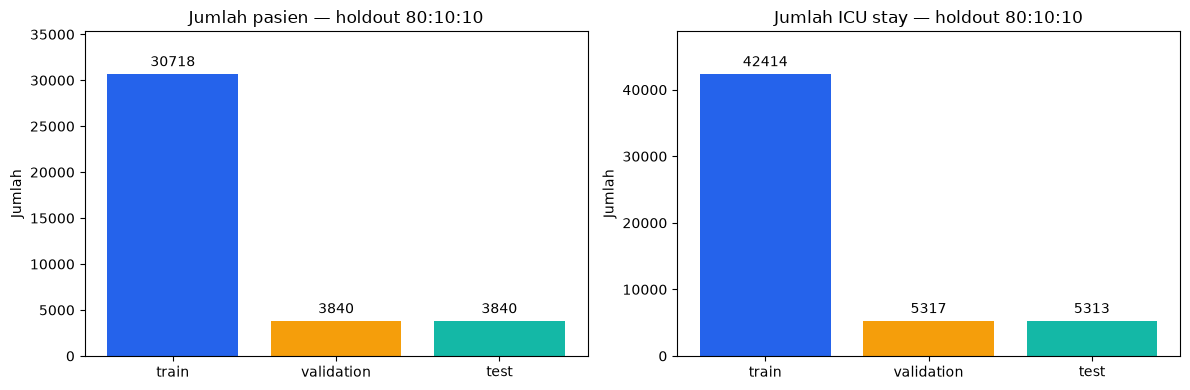

ICU LOS v2 — STEP03 HOLDOUT 80:10:10
Run: 20261103_042028_946805_preprocess_80_10_10
Cohort: 53,044 stays; 38,398 patients
Patient-level random split; seed 42; no cross-validation.
All stays of one patient belong to the same subset.
Validation/test patient counts rounded up; remaining patients used for training.
Train-only medians, mean/std and categorical vocabulary.
Measurements: causal forward fill then train median; volumes: train median without forward fill.
43 temporal features; original observation masks preserved.
Normalized partitions: 415 (one holdout set).
No BERT encoding, graph construction, model training or test scoring.
Checks: 22 PASS
Status: SPLIT_PREPROCESS_COMPLETE_READY_FOR_TEXT_EMBEDDINGS
Reports: C:\Users\ASUS\Documents\icu_los\outputs\20261103_042028_946805_preprocess_80_10_10


In [28]:
summary = split_summary.set_index("split").loc[list(ROLES)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#2563eb", "#f59e0b", "#14b8a6"]
for ax, field, title in zip(
    axes, ["patients", "icu_stays"], ["Jumlah pasien", "Jumlah ICU stay"]
):
    bars = ax.bar(summary.index, summary[field], color=colors)
    ax.bar_label(bars, fmt="%d", padding=3)
    ax.set(title=title + " — holdout 80:10:10", ylabel="Jumlah")
    ax.margins(y=0.15)
fig.tight_layout()
plt.show()
print((report_dir / "summary.txt").read_text(encoding="utf-8"))


## Hasil dan langkah berikutnya
Artefak utama:

| File | Isi |
|---|---|
| `split_summary.csv` | Jumlah pasien dan stay setiap subset |
| `quality_checks.csv` | Hasil pemeriksaan |
| `temporal_parameters.csv` | Median dan parameter normalisasi train |
| `input_package.json` | Kontrak input untuk tahap berikutnya |
| `patient_split_LOCAL.csv` | Pemetaan pasien ke subset, simpan lokal |
| `split_assignments_LOCAL.csv` | Pemetaan stay ke subset, simpan lokal |
| `holdout/` | Parameter dan nilai terstruktur hasil transformasi |

**Step04 dan Step05 lama harus disesuaikan dengan kontrak holdout baru.** Paket ini memakai `structured_inputs`, tidak memakai registry `folds`. Jangan mengganti hash paket lama atau mengarahkan checkpoint lima-fold ke paket ini.

Embedding Bio-ClinicalBERT yang sudah selesai dapat digunakan kembali jika cohort, teks, encoder dan urutan ID cocok; metadata keterkaitannya perlu diperbarui secara terverifikasi pada Step04. Notebook ini belum melakukan migrasi embedding, training model, atau evaluasi test.

Setelah selesai, bagikan `summary.txt`, `quality_checks.csv`, dan `split_summary.csv` untuk pemeriksaan. Simpan notebook agar tampilan hasil tetap tersedia.
